# Ethiopia Food Prices — 03 EDA
**Exploratory Data Analysis**

Builds on the cleaned dataset from `01_02_data_cleaning_and_preprocessing.ipynb`. We look at overall
trends, regional differences, seasonality, commodity behaviour, and the retail/wholesale relationship —
setting up the questions that `04 SPIKE ANALYSIS` and the later forecasting notebooks will answer.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 20)

df = pd.read_csv('../data/eth_food_prices_clean.csv', parse_dates=['date'])
print(f'{len(df):,} rows x {df.shape[1]} columns  |  {df.date.min().date()} -> {df.date.max().date()}')

# Food-only view, used for most of the analysis below
food = df[df['category'] != 'non-food'].copy()
print(f'Food-only rows: {len(food):,}  ({df.category.nunique()} categories total, incl. non-food)')


62,875 rows x 21 columns  |  2000-01-15 -> 2026-07-15
Food-only rows: 59,997  (8 categories total, incl. non-food)


## 3.1 How much data do we actually have, and when?

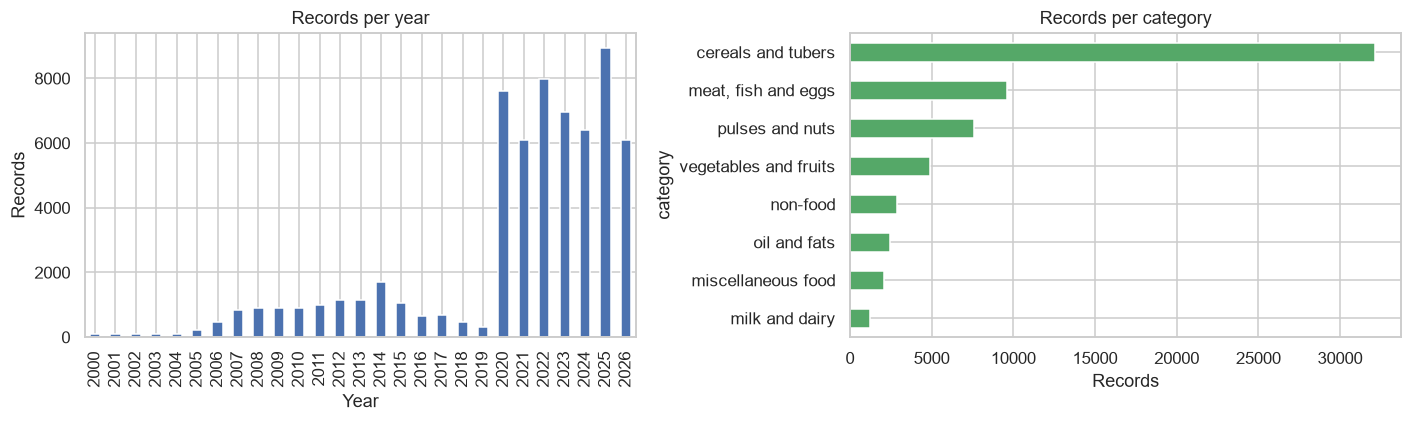

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df.groupby(df['date'].dt.year).size().plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Records per year')
axes[0].set_xlabel('Year'); axes[0].set_ylabel('Records')

df.groupby('category', observed=True).size().sort_values().plot(kind='barh', ax=axes[1], color='#55A868')
axes[1].set_title('Records per category')
axes[1].set_xlabel('Records')

plt.tight_layout()
plt.show()


Reporting volume jumps sharply from 2020 onward as WFP expanded market monitoring in Ethiopia — this is
a data-collection effect, not a real-world change, and matters for how much we should trust pre-2020 trend
estimates. `cereals and tubers` dominates the dataset by record count, reflecting both how many distinct
cereal commodities are tracked and how central staples are to WFP price monitoring.


## 3.2 National price trend for key staples

Note: retail-market teff is reported by variety (`Teff (mixed)`, `Teff (white)`, ...) — the plain `Teff`
label in this dataset is wholesale-only — so `Teff (mixed)` (the best-covered retail variety) is used below
as the representative teff series. Likewise `Rice (imported)` has very sparse retail coverage, so the more
complete `Rice` series is used instead.


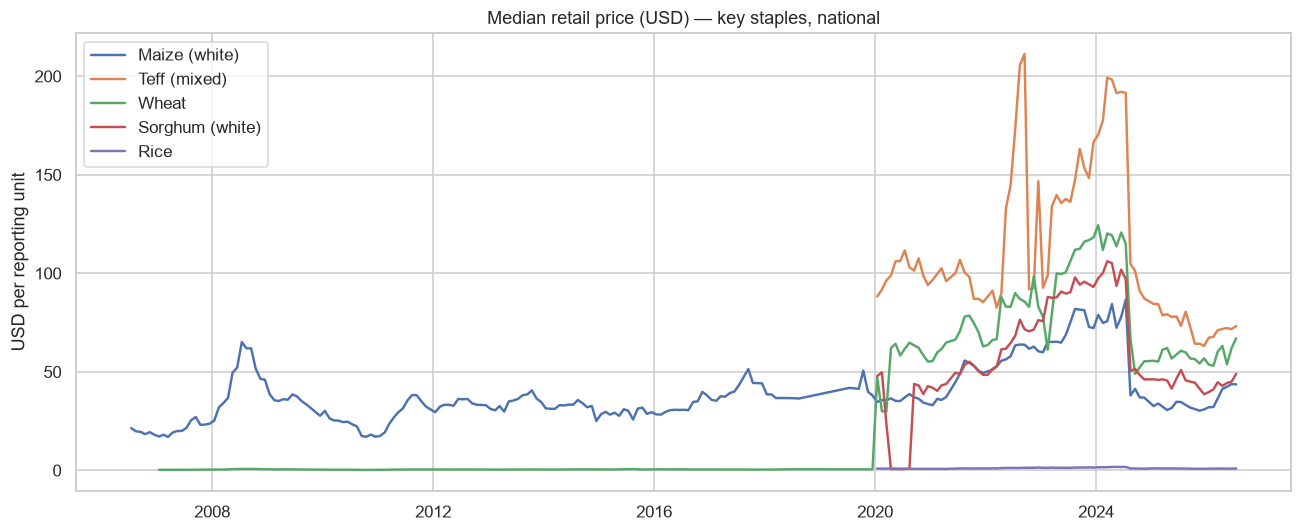

In [11]:
staples = ['Maize (white)', 'Teff (mixed)', 'Wheat', 'Sorghum (white)', 'Rice']

fig, ax = plt.subplots(figsize=(12, 5))
for s in staples:
    sub = food[(food['commodity'] == s) & (food['pricetype'] == 'Retail')]
    monthly = sub.groupby('date')['usdprice'].median()
    if len(monthly) > 5:
        ax.plot(monthly.index, monthly.values, label=s, linewidth=1.6)

ax.set_title('Median retail price (USD) — key staples, national')
ax.set_ylabel('USD per reporting unit')
ax.legend()
plt.tight_layout()
plt.show()


Prices in USD terms still show a strong long-run climb for most staples, on top of visible short-term
swings. Because `usdprice` already nets out ETB currency depreciation, this upward drift reflects **real**
commodity cost pressure (production shocks, conflict-driven disruption, global food price cycles) rather
than just currency effects — the ETB view below shows how much larger the move looks before removing the
currency effect.


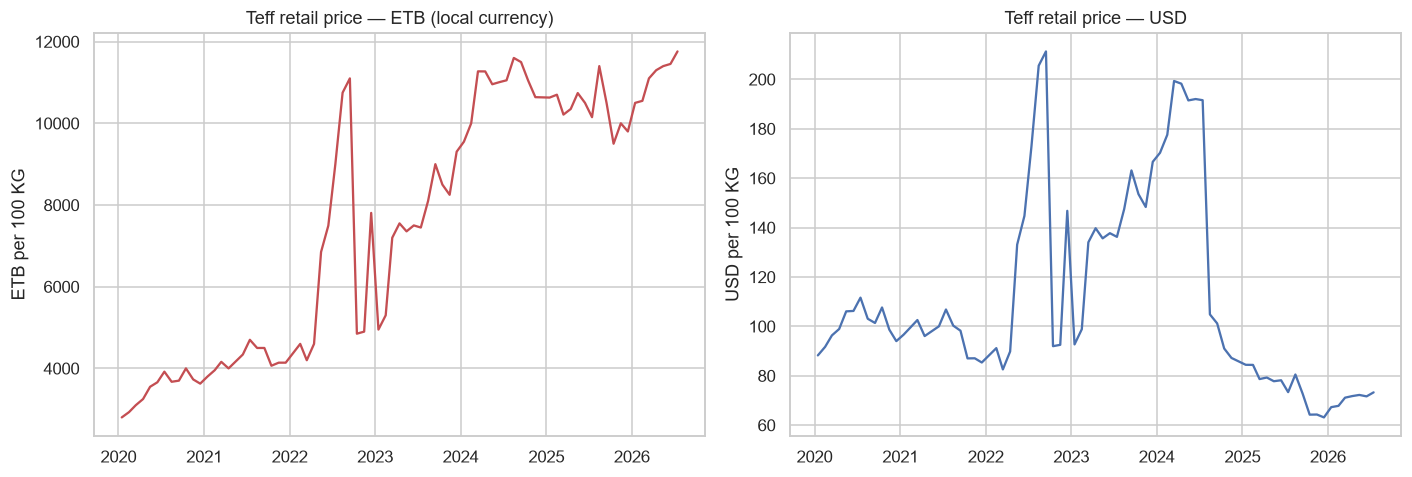

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)

teff = food[(food['commodity'] == 'Teff (mixed)') & (food['pricetype'] == 'Retail')]
teff_etb = teff.groupby('date')['price'].median()
teff_usd = teff.groupby('date')['usdprice'].median()

axes[0].plot(teff_etb.index, teff_etb.values, color='#C44E52')
axes[0].set_title('Teff retail price — ETB (local currency)')
axes[0].set_ylabel('ETB per 100 KG')

axes[1].plot(teff_usd.index, teff_usd.values, color='#4C72B0')
axes[1].set_title('Teff retail price — USD')
axes[1].set_ylabel('USD per 100 KG')

plt.tight_layout()
plt.show()


The ETB series rises far more steeply than the USD series — a large share of the ETB price increase is
currency depreciation (especially the sharp step after Ethiopia's July 2024 exchange-rate liberalization),
not purely food-cost inflation. **This is why `usdprice` is generally the safer series for cross-year
comparisons**, and why the spike-analysis notebook needs to be explicit about which currency basis a
"spike" is measured in.


## 3.3 Regional price differences

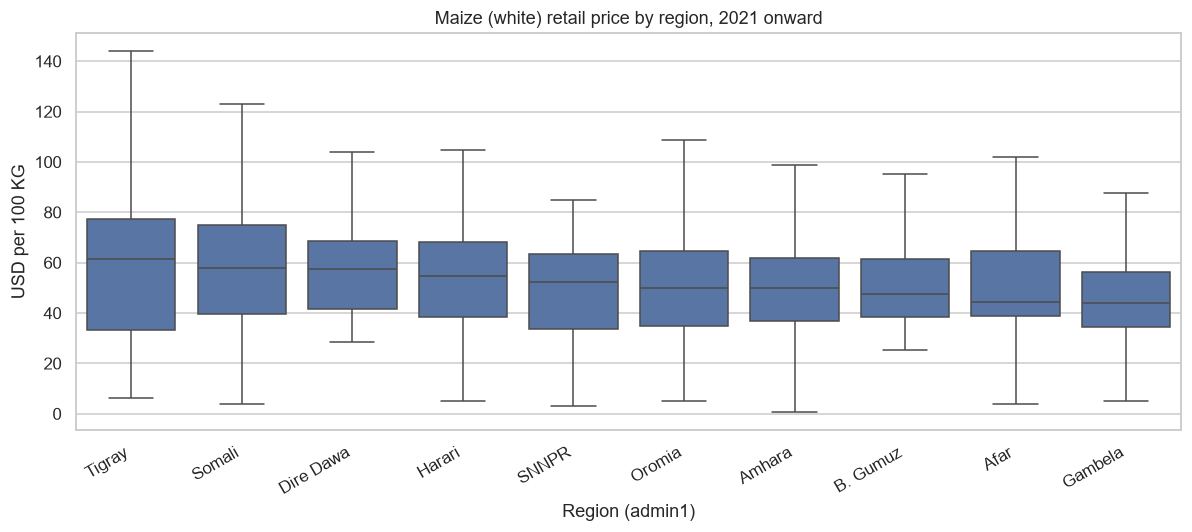

In [13]:
commodity_focus = 'Maize (white)'
sub = food[(food['commodity'] == commodity_focus) & (food['pricetype'] == 'Retail') & (food['date'] >= '2021-01-01')]

order = sub.groupby('admin1', observed=True)['usdprice'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=sub, x='admin1', y='usdprice', order=order, ax=ax, showfliers=False)
ax.set_title(f'{commodity_focus} retail price by region, 2021 onward')
ax.set_xlabel('Region (admin1)')
ax.set_ylabel('USD per 100 KG')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


Median prices for the same commodity differ noticeably across regions — a mix of transport cost from
production areas, local supply/demand, and market-access disruption in conflict-affected regions. This
regional spread is one reason a single national average can hide a lot of what's actually happening on the
ground, and it motivates keeping `admin1`/`market` as first-class dimensions in the forecasting work later
in the project.


## 3.4 Retail vs. wholesale

Wholesale reporting is much thinner than retail overall, and not every retail variety has a matching
wholesale series. `Teff (white)` and `Wheat (white)` are used here instead of the `Teff (mixed)` / `Wheat`
series from above, since they are the varieties with usable wholesale coverage.


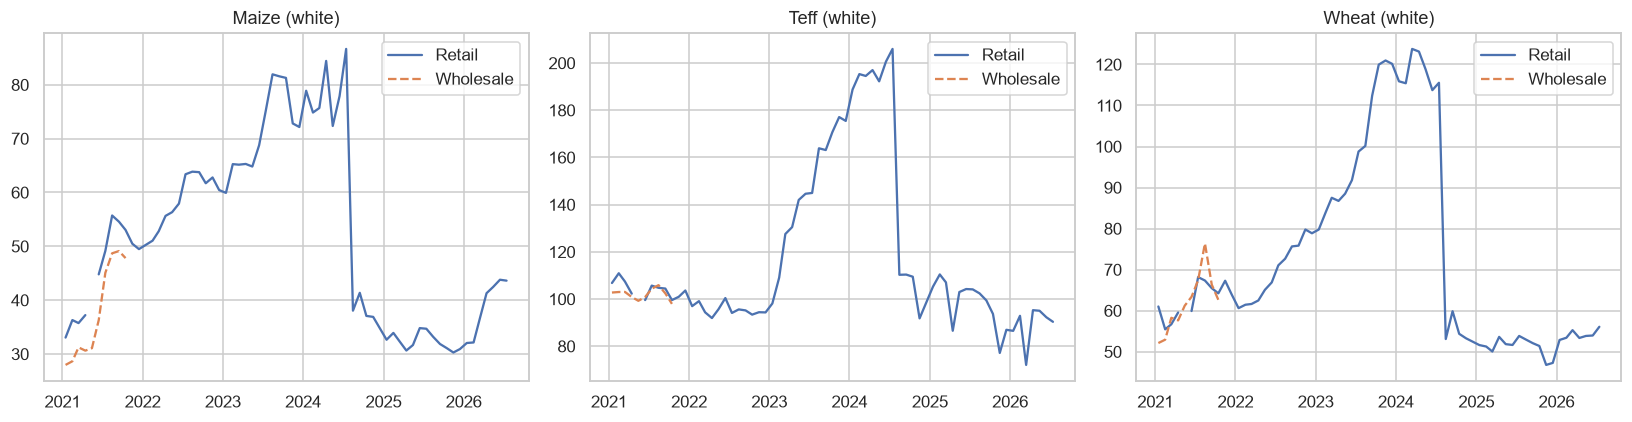

In [6]:
rw = food[food['commodity'].isin(['Maize (white)', 'Teff (white)', 'Wheat (white)']) & (food['date'] >= '2021-01-01')]
pivot = rw.pivot_table(index='date', columns=['commodity', 'pricetype'], values='usdprice', aggfunc='median')

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, c in zip(axes, ['Maize (white)', 'Teff (white)', 'Wheat (white)']):
    for pt, style in [('Retail', '-'), ('Wholesale', '--')]:
        if (c, pt) in pivot.columns:
            ax.plot(pivot.index, pivot[(c, pt)], style, label=pt)
    ax.set_title(c)
    ax.legend()
plt.tight_layout()
plt.show()


Retail sits consistently above wholesale, as expected (the retail markup), and the two track each other closely — wholesale price movements are a legitimate leading/contemporaneous signal for retail, which is useful for feature engineering later on.

## 3.5 Seasonality

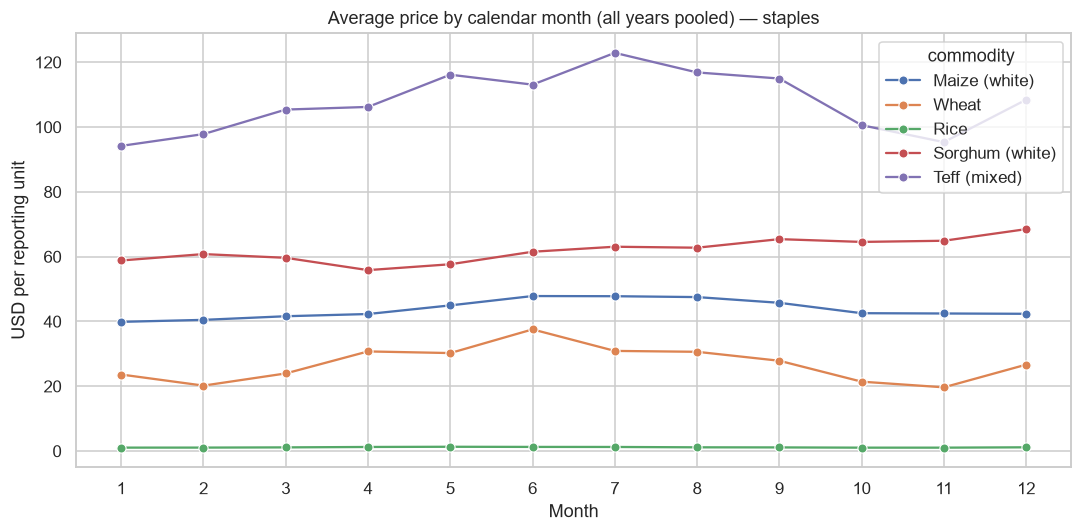

In [7]:
seasonal = food[food['commodity'].isin(staples) & (food['pricetype'] == 'Retail')].copy()
seasonal['month'] = seasonal['date'].dt.month

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=seasonal, x='month', y='usdprice', hue='commodity', marker='o', ax=ax, errorbar=None)
ax.set_xticks(range(1, 13))
ax.set_title('Average price by calendar month (all years pooled) — staples')
ax.set_xlabel('Month'); ax.set_ylabel('USD per reporting unit')
plt.tight_layout()
plt.show()


Pooling across years like this mixes seasonal effects with the strong multi-year upward trend, so it's
a rough first look rather than a clean seasonal signal — `05 TIME SERIES` should detrend before drawing
seasonal conclusions (e.g. STL decomposition). Even so, harvest-adjacent months for cereals tend to sit
lower than the pre-harvest lean season, which is the pattern we'd expect from agronomy.


## 3.6 Commodity price volatility (relative)

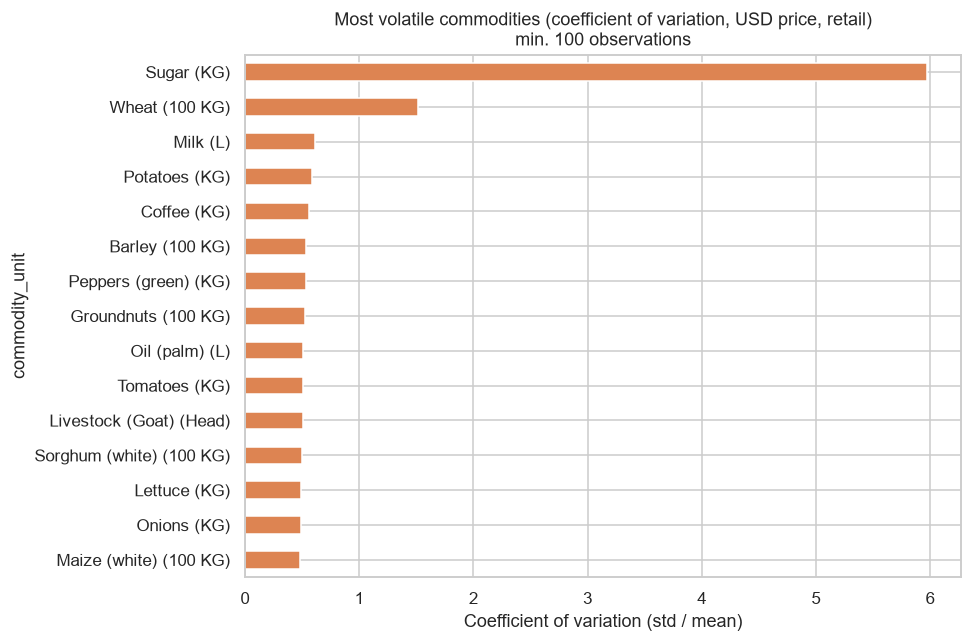

In [8]:
vol = (
    food[food['pricetype'] == 'Retail']
    .groupby('commodity_unit', observed=True)
    .filter(lambda g: len(g) >= 100)
    .groupby('commodity_unit', observed=True)['usdprice']
    .agg(['mean', 'std'])
)
vol['cv'] = vol['std'] / vol['mean']
top_volatile = vol.sort_values('cv', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 6))
top_volatile['cv'].sort_values().plot(kind='barh', ax=ax, color='#DD8452')
ax.set_title('Most volatile commodities (coefficient of variation, USD price, retail)\nmin. 100 observations')
ax.set_xlabel('Coefficient of variation (std / mean)')
plt.tight_layout()
plt.show()


Coefficient of variation ranks commodities by *relative* price volatility (so a cheap, spiky commodity isn't drowned out by an expensive stable one) — this ranking is a natural shortlist of commodities to prioritize in `04 SPIKE ANALYSIS`.

## 3.7 Correlation between staple commodities

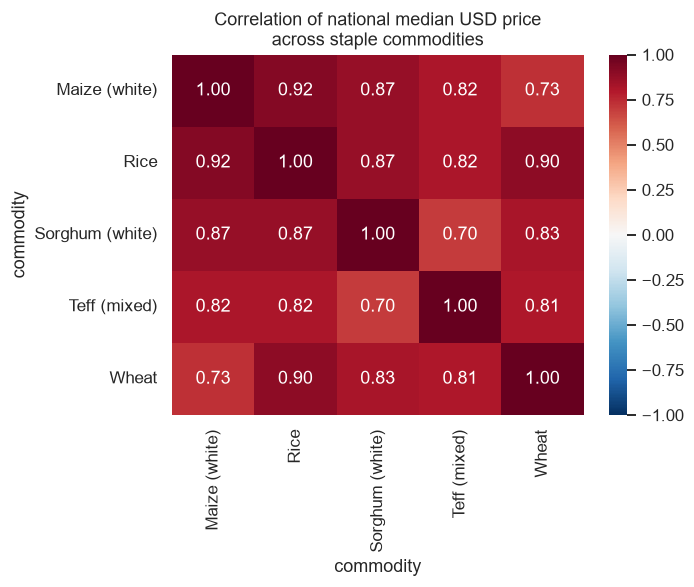

In [9]:
corr_data = (
    food[food['commodity'].isin(staples) & (food['pricetype'] == 'Retail')]
    .pivot_table(index='date', columns='commodity', values='usdprice', aggfunc='median')
    .dropna(how='all')
)
corr = corr_data.corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlation of national median USD price\nacross staple commodities')
plt.tight_layout()
plt.show()


Staple cereal prices move together fairly strongly nationally, consistent with shared drivers (currency, fuel/transport cost, macro food inflation) rather than fully independent commodity-specific cycles — useful context for feature engineering (a shared macro trend feature may explain a lot on its own).

---
## Summary — what EDA tells us to carry forward

- **Use `usdprice`, not raw ETB `price`**, for anything comparing across years — ETB depreciation otherwise
  dominates the signal.
- **Reporting coverage is uneven over time**: pre-2020 should be treated as thin/low-confidence in any
  trend or seasonality estimate.
- **Region matters**: the same commodity can trade at meaningfully different prices across `admin1`, so
  regional or market-level modelling will likely beat a single national series.
- **Retail and wholesale track together**, with retail consistently above wholesale — wholesale is a
  candidate leading feature.
- **Staple prices are highly cross-correlated nationally**, suggesting a shared macro component worth
  isolating in feature engineering.
- A short list of **high coefficient-of-variation commodities** is a good starting point for the spike
  analysis in the next notebook.
